# My color portrait as an energy minimum

I start with a shuffled color portrait and let it relax toward its original image. I treat red, green and blue as three independent signed fields. The fixed target r is explicitly included in the energy; this is an image analogy, not recovery of an unknown face. Every quantity is dimensionless.

I develop this calculation in small steps. I run a cell, inspect its result and test it before adding the next part. Run the cells in order in Jupyter. A code cell defines a part of the calculation or carries it out; defining a function does not run it.

I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research and commercial use require my written permission. Earlier licensed releases retain their permissions. [Read the code-use terms](https://saswataiith.github.io/using-my-resources/).

Copyright (c) 2026 Saswata Bhattacharyya.

## 1. Prepare the Python environment

I install the packages listed in the next cell once in the same environment as the notebook. In Jupyter or Colab, remove the comment marker from the installation line below if a package is missing. NumPy stores arrays and evaluates numerical operations. Matplotlib displays plots. Pillow reads and writes images. This installation does not change the model parameters.

In [1]:
# %pip install numpy "pillow>=10.1" matplotlib
import numpy as np
assert np.isfinite(np.array([0.0, 1.0])).all()
print("NumPy is ready:", np.__version__)

NumPy is ready: 2.1.3


## 2. Read the image and check its dimensions

I download my public portrait once, or replace this path with my own image. An RGB array has two position axes and one channel axis. The three channels are red, green and blue.

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

work = Path("lesson-data")
work.mkdir(exist_ok=True)

def get_file(relative_path):
    # I download a public example only when its local copy is missing.
    destination = work / Path(relative_path).name
    if not destination.exists():
        urlretrieve("https://saswataiith.github.io/" + relative_path, destination)
    return destination

portrait = get_file("assets/images/saswata-landscape.png")
output = "portrait-minimum-results"

## 3. Import arrays and image operations

I use NumPy for numerical arrays and Pillow for reading images and writing labeled frames. Path handles file locations. The script also imports argparse for its command-line interface; the notebook does not use that interface.

In [3]:
from pathlib import Path
import argparse
import numpy as np
from PIL import Image, ImageDraw, ImageFont

## 4. Choose a portable display font

I try the original font, then DejaVu Sans, then Pillow's default font. The font changes labels on the image only; it does not change a numerical field.

In [4]:
def portrait_font(size):
    fonts = [Path('/') / 'System' / 'Library' / 'Fonts' / 'Helvetica.ttc', 'DejaVuSans.ttf']
    for font in fonts:
        try:
            return ImageFont.truetype(str(font), size)
        except OSError:
            pass
    return ImageFont.load_default(size=size)

## 5. Read and shuffle the color pixels

I call the fixed portrait target and the shuffled portrait initial. Each signed RGB channel ranges from −1 to 1. I shuffle whole pixels with seed 19, preserving the three channel means.

In [5]:
def prepare_portrait(path, color=False):
    mode = 'RGB' if color else 'L'
    image = Image.open(path).convert(mode).resize((256, 256))
    target = np.asarray(image, dtype=float) / 127.5 - 1
    rng = np.random.default_rng(19)
    if color:
        initial = rng.permutation(target.reshape(-1, 3), axis=0).reshape(target.shape)
    else:
        initial = rng.permutation(target.ravel()).reshape(target.shape)
    return (target, initial)

## 6. Write the evolution rule

I calculate the Fourier wave numbers and the squared magnitude k2. For portrait restoration, the error is the current field minus the fixed target. The Allen–Cahn error decays locally; the Cahn–Hilliard Fourier modes decay at rates proportional to k2. The spatial transform leaves the channel axis unchanged.

In [6]:
def evolve(target, initial, time):
    k = 2 * np.pi * np.fft.fftfreq(256, d=32 / 256)
    k2 = k[:, None] ** 2 + k[None, :] ** 2
    if target.ndim == 3:
        k2 = k2[:, :, None]
    error = initial - target
    transformed_error = np.fft.fft2(error, axes=(0, 1))
    ac = target + error * np.exp(-0.03 * time)
    ch = target + np.fft.ifft2(transformed_error * np.exp(-1e-05 * k2 * time), axes=(0, 1)).real
    return (ac, ch)

## 7. Check the shuffle before evolving anything

I prepare the target r and starting field u0 as 256 × 256 × 3 arrays. I check that each channel has the same mean before and after shuffling. I display the two arrays side by side; signed values are mapped back to display colors only.

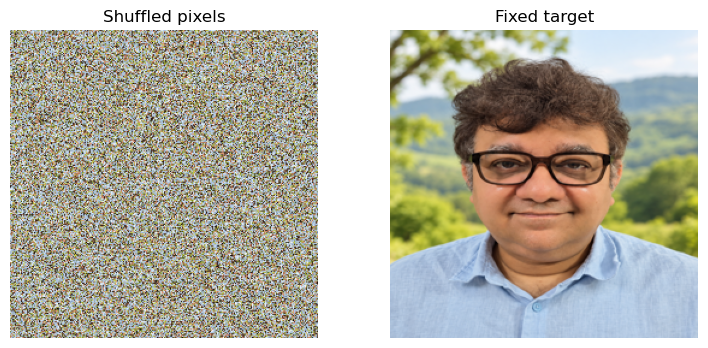

Channel means: [0.25635938 0.23498763 0.09989325]


In [7]:
target, initial = prepare_portrait(portrait, color=True)
assert target.shape == initial.shape == (256, 256, 3)
assert np.allclose(initial.mean((0, 1)), target.mean((0, 1)), atol=1e-13, rtol=0)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, field, title in zip(axes, (initial, target), ("Shuffled pixels", "Fixed target")):
    ax.imshow(np.clip((field + 1) / 2, 0, 1))
    ax.set_title(title)
    ax.axis("off")
plt.show()
print("Channel means:", initial.mean((0, 1)))

## 8. Define energy and verify its minimum

I choose $F=\tfrac12\int_\Omega\sum_j(u_j-r_j)^2\,dA$. Here $j$ identifies an RGB channel, $\Omega$ is the image domain and $dA$ is an area element. The mean energy density below is $F/(3|\Omega|)$. Every squared difference is nonnegative, so the minimum is exactly $F=0$ when $u=r$. This is the number zero. A finite-time solution approaches this minimum asymptotically.

In [8]:
def mean_energy(field):
    return 0.5 * np.mean((field - target)**2)
assert mean_energy(target) == 0.0
assert mean_energy(initial) > 0.0
print("Target energy:", mean_energy(target))
print("Initial energy:", mean_energy(initial))

Target energy: 0.0
Initial energy: 0.2203078196211593


## 9. Take one step and compare the two laws

For channel $j$, Allen–Cahn gives $\partial_tu_j=-L(u_j-r_j)$, with $L=0.03$. Cahn–Hilliard gives $\partial_tu_j=M\nabla^2(u_j-r_j)$, with $M=10^{-5}$. Here $t$ is dimensionless time and $\nabla^2$ is the spatial Laplacian. This local quadratic energy gives a second-order conserved equation; a gradient energy would supply the familiar fourth-order term. I use the exact propagators at time 100.

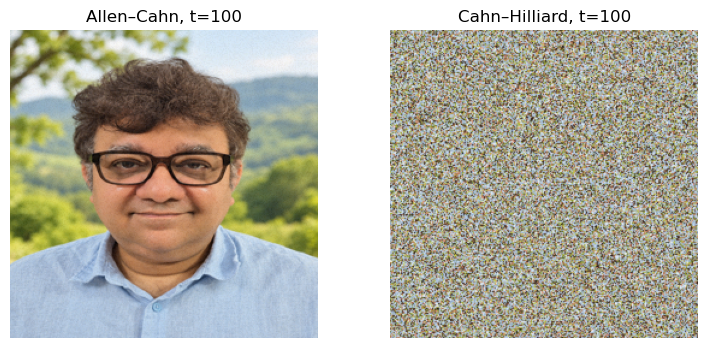

In [9]:
ac, ch = evolve(target, initial, 100.0)
assert mean_energy(ac) <= mean_energy(initial)
assert mean_energy(ch) <= mean_energy(initial)
assert np.allclose(ch.mean((0, 1)), initial.mean((0, 1)), atol=2e-13, rtol=0)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, field, title in zip(axes, (ac, ch), ("Allen–Cahn, t=100", "Cahn–Hilliard, t=100")):
    ax.imshow(np.clip((field + 1) / 2, 0, 1))
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 10. Test mean drift separately from motion

I add a spatially uniform offset of 0.1 to the target. Allen–Cahn removes this mean offset exponentially. Cahn–Hilliard preserves it. Neither rule translates the fixed target across the image. Other Allen–Cahn energies can drive interface motion; this example does not test that.

In [10]:
offset_ac, offset_ch = evolve(target, target + 0.1, 100.0)
assert np.allclose(offset_ac - target, 0.1 * np.exp(-0.03 * 100), atol=1e-14)
assert np.allclose(offset_ch - target, 0.1, atol=1e-14)
print("AC remaining offset:", (offset_ac - target).mean())
print("CH remaining offset:", (offset_ch - target).mean())

AC remaining offset: 0.004978706836786389
CH remaining offset: 0.10000000000000003


## 11. Save the complete portrait sequence

I keep the original grid, seed, time samples and exact propagators. Each saved row contains time, channel means and energy density. The output folder contains 241 image frames and diagnostics.csv. The movie uses nonuniform simulation times, so its playback speed is not a physical rate comparison.

In [11]:
def run_example(portrait, output, color=False):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    target, initial = prepare_portrait(portrait, color)
    font, small = (portrait_font(25), portrait_font(22))
    records = []
    times = np.r_[0, np.geomspace(0.1, 30000000.0, 240)]
    for index, time in enumerate(times):
        ac, ch = evolve(target, initial, time)
        energies = [0.5 * np.mean((field - target) ** 2) for field in [ac, ch]]
        if color:
            means = [*ac.mean(axis=(0, 1)), *ch.mean(axis=(0, 1))]
        else:
            means = [ac.mean(), ch.mean()]
        records.append([time, *means, *energies])
        frame = Image.new('RGB', (1160, 754), '#f5f7f2')
        draw = ImageDraw.Draw(frame)
        draw.text((24, 14), 'MY PORTRAIT IS THE ENERGY MINIMUM', font=font, fill='#173d40')
        draw.text((24, 51), f'Forward relaxation | time {time:.3g} | L=0.03, M=0.00001 | nonuniform time sampling', font=small, fill='#173d40')
        for x, field, title, energy in [(24, ac, 'Allen-Cahn | nonconserved', energies[0]), (604, ch, 'Cahn-Hilliard | conserved', energies[1])]:
            draw.text((x, 99), title, font=small, fill='#173d40')
            pixels = np.uint8(np.clip((field + 1) * 127.5, 0, 255))
            frame.paste(Image.fromarray(pixels).resize((528, 528)), (x, 139))
            if color:
                draw.text((x, 687), f'F / (3 x area): {energy:.3e}', font=small, fill='#173d40')
                rgb = field.mean(axis=(0, 1))
                draw.text((x, 718), 'Mean R/G/B: ' + ' / '.join((f'{v:+.3f}' for v in rgb)), font=small, fill='#173d40')
            else:
                draw.text((x, 687), f'Energy / area: {energy:.7f}', font=small, fill='#173d40')
                draw.text((x, 718), f'Mean field: {field.mean():+.5f}', font=small, fill='#173d40')
        frame.save(output / f'frame-{index:03d}.png')
    initial_mean = initial.mean(axis=(0, 1))
    assert np.max(np.abs(ch.mean(axis=(0, 1)) - initial_mean)) < 1e-10
    assert max(energies) < 1e-06
    if color:
        header = 'time,AC_R_mean,AC_G_mean,AC_B_mean,CH_R_mean,CH_G_mean,CH_B_mean,AC_energy_per_area_per_channel,CH_energy_per_area_per_channel'
    else:
        header = 'time,AC_mean,CH_mean,AC_energy_per_area,CH_energy_per_area'
    np.savetxt(output / 'diagnostics.csv', records, delimiter=',', header=header, comments='')
    print('Final energy densities:', energies)
    print('CH maximum channel mean drift:', np.max(np.abs(ch.mean(axis=(0, 1)) - initial_mean)))

## 12. Save the original 241-frame color calculation

I now use the complete frame writer defined in the preceding cell. I preserve the original nonuniform sample times, ending at 30,000,000. The PNG files and diagnostics.csv are written in the chosen output folder. Frames are not uniformly spaced in simulation time.

In [12]:
run_example(portrait, output, color=True)

Final energy densities: [np.float64(0.0), np.float64(3.8152048054083335e-12)]
CH maximum channel mean drift: 1.2245759961615477e-13


## 13. Plot energy and check every saved mean

I read the measured diagnostics, rather than infer conservation from the colors. Both energy sequences must be nonincreasing within the stated round-off tolerance. Each Cahn–Hilliard channel mean must remain within 2×10⁻¹³ of its initial value.

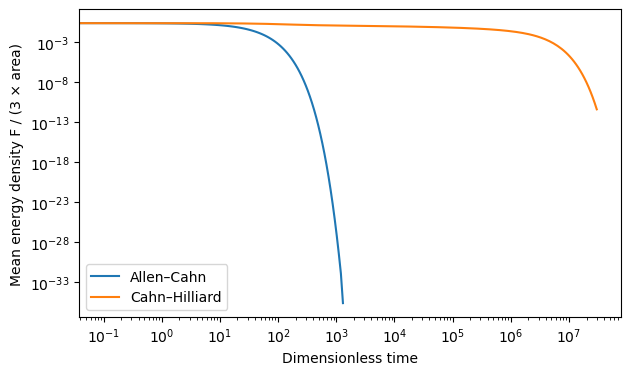

Final mean energy densities: [0.00000000e+00 3.81520481e-12]


In [13]:
records = np.loadtxt(Path(output) / "diagnostics.csv", delimiter=",", skiprows=1)
assert records.shape == (241, 9)
assert np.isfinite(records).all()
assert np.max(np.abs(records[:, 4:7] - records[0, 4:7])) < 2e-13
assert np.max(np.diff(records[:, 7:9], axis=0)) < 1e-15
plt.figure(figsize=(7, 4))
for col, name in [(7, "Allen–Cahn"), (8, "Cahn–Hilliard")]:
    positive = records[:, col] > 0
    plt.loglog(records[positive, 0], records[positive, col], label=name)
plt.xlabel("Dimensionless time")
plt.ylabel("Mean energy density F / (3 × area)")
plt.legend()
plt.show()
print("Final mean energy densities:", records[-1, 7:9])

## 14. Review and extend the calculation

I first restart the kernel and run all the required cells. Then I change one input, predict its effect and compare the result with that prediction. A successful check establishes the tested property; it does not establish convergence or equilibrium. I retain the [complete script](https://saswataiith.github.io/files/mesoscale/examples/portrait_energy_minimum.py) for command-line use. The notebook embeds the calculation directly and does not need that script to run.